# Bell-prep fusion surgery

`BUILDERS["surgery_bell_prep_fusion"]` step by step: SED → split seam → Bell-prep gadgets → realisation → experiment → circuit, then the erasure interface and a small pure fusion-erasure sweep.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from dizx.builders import BUILDERS, surgery_layers
from dizx.circuit_extractor import to_stim
from dizx.dem_view import plot_dem
from dizx.realisation import QECExperiment, RealisedSED
from dizx.schedules import RotatedSurfaceCodeSchedule
from dizx.surgery import two_patch_surgery
from walkthrough import erasure, erasure_sweep, full_and_seam, plot_sweep
from dizx.builders import bell_prep_gadgets
from dizx.surgery import straight_interface

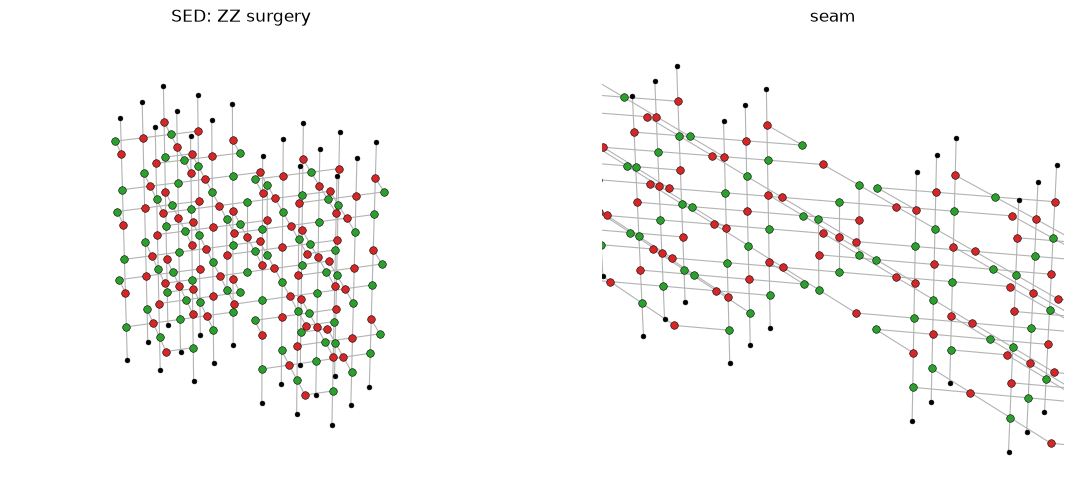

In [2]:
d, n = 3, 1
s = two_patch_surgery(d, "ZZ", layers=surgery_layers(n))
full_and_seam(s.sed, d, "SED: ZZ surgery")

## Split the seam generators across the two units

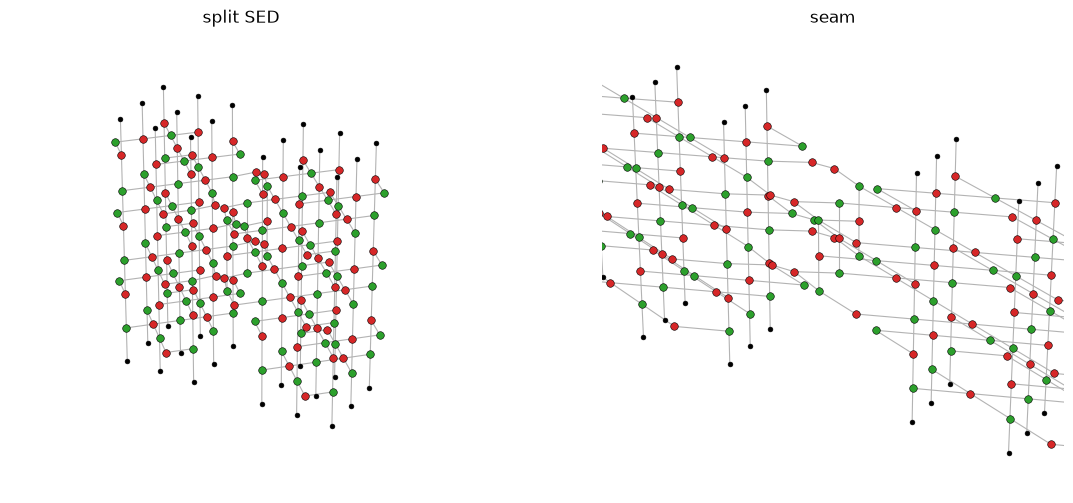

In [3]:
split = s.split_seam(straight_interface(d))
full_and_seam(split, d, "split SED")

## Bell-prep gadget on each split

each half emits a photon `f`, and the photons are fused: `n1 -- f1 == f2 -- n2`

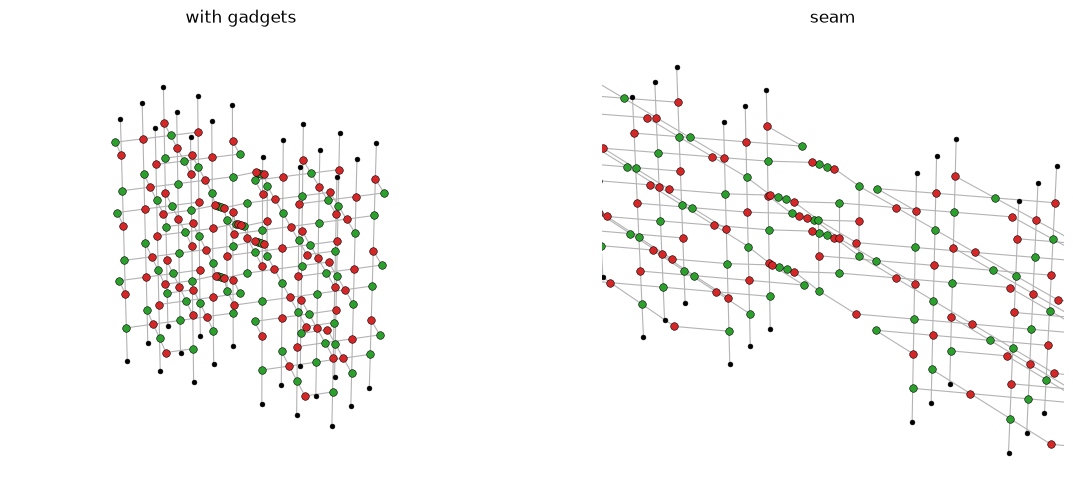

In [4]:
sed, region = bell_prep_gadgets(split)
full_and_seam(sed, d, "with gadgets")

## Realisation: circuit-based, gadget qubits as resource states

5 fusions


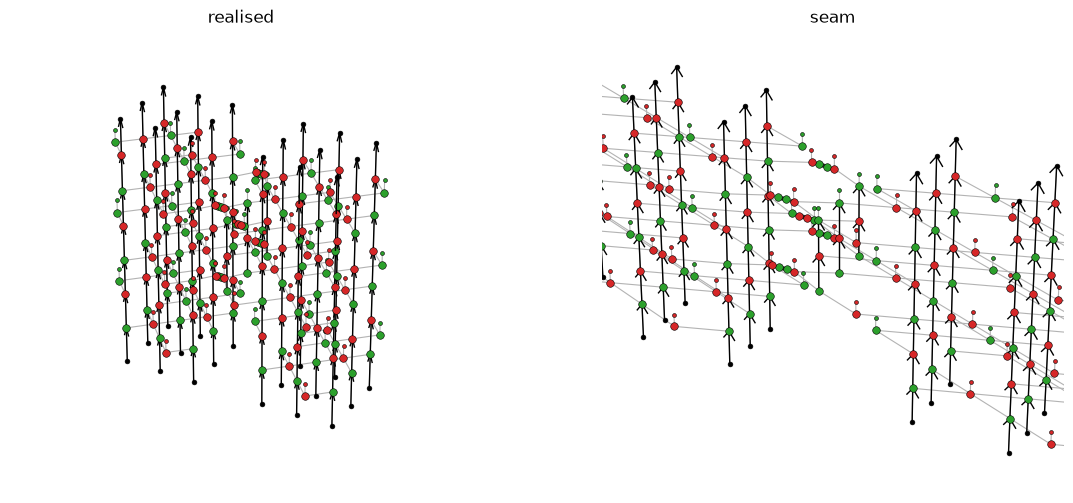

In [5]:
real = RealisedSED.circuit_based(sed, links="fusion")
real.graph_region = region
print(sum(l.kind == "fusion" for l in real.links), "fusions")
full_and_seam(real, d, "realised")

## Experiment and circuit

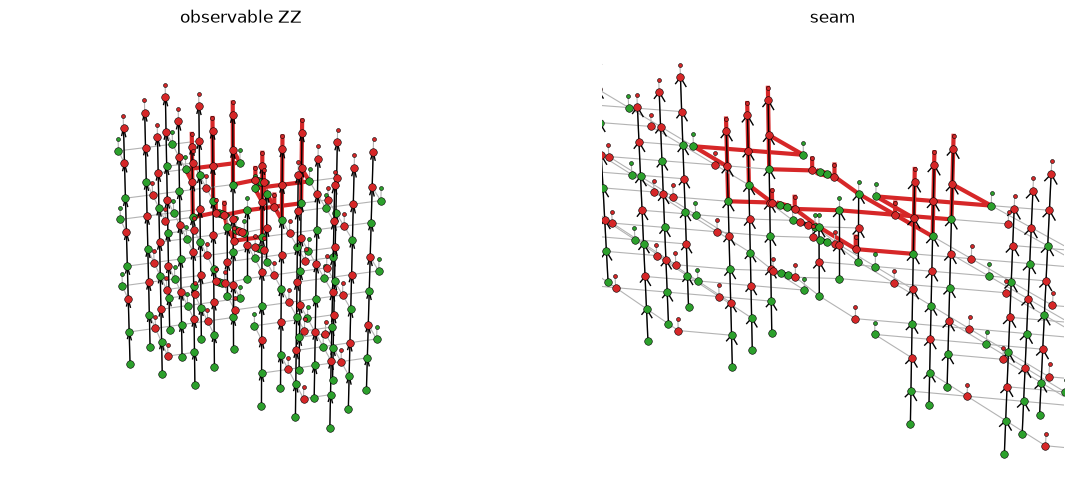

In [6]:
def experiment(real, observable):
    """Patches prepared in X (ZZ merge), measured in the observable's basis."""
    return QECExperiment(real, {p: "X" for p in real.inputs},
                         {p: observable[0] for p in real.outputs})


exp = experiment(real, "ZZ")
full_and_seam(exp, d, "observable ZZ", web=exp.observables[0])

In [7]:
circuit = to_stim(exp, RotatedSurfaceCodeSchedule(s.merged), fusions="gates")
assert circuit == BUILDERS["surgery_bell_prep_fusion"](distance=d, n_cycles=n).circuit
circuit.num_qubits, circuit.num_detectors

(51, 52)

## Interface DEM (fusion erasure)

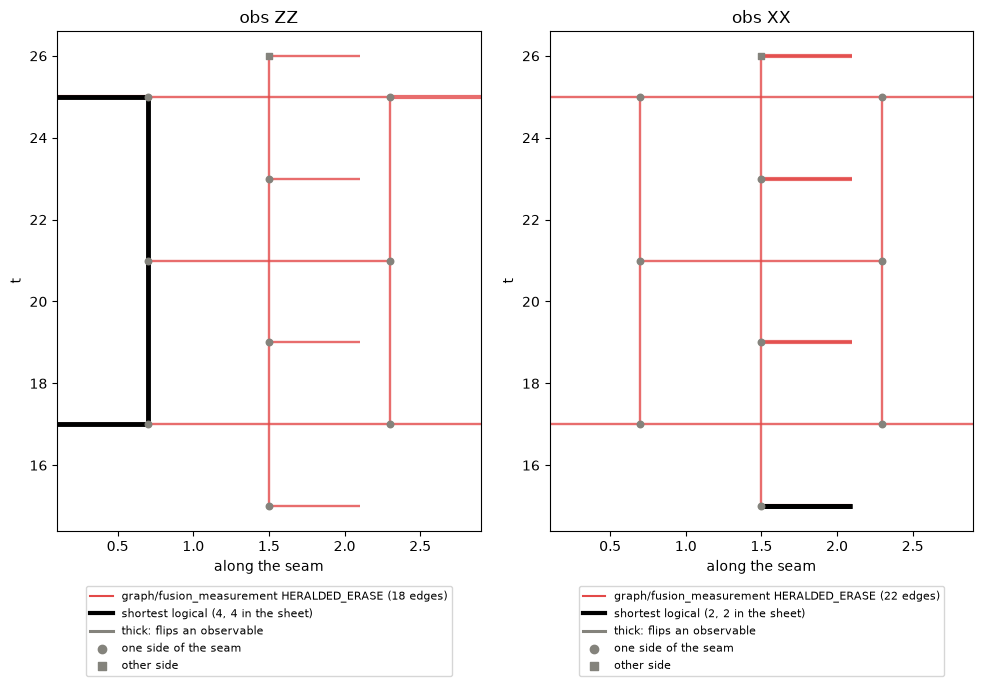

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 7))
for ax, obs in zip(axes, ("ZZ", "XX")):
    plot_dem(BUILDERS["surgery_bell_prep_fusion"](distance=3, n_cycles=3, observable=obs).circuit, erasure(("graph", "fusion_measurement"), 0.1), ax=ax, sheet=True, title=f"obs {obs}")
fig.tight_layout()

## Pure erasure sweep

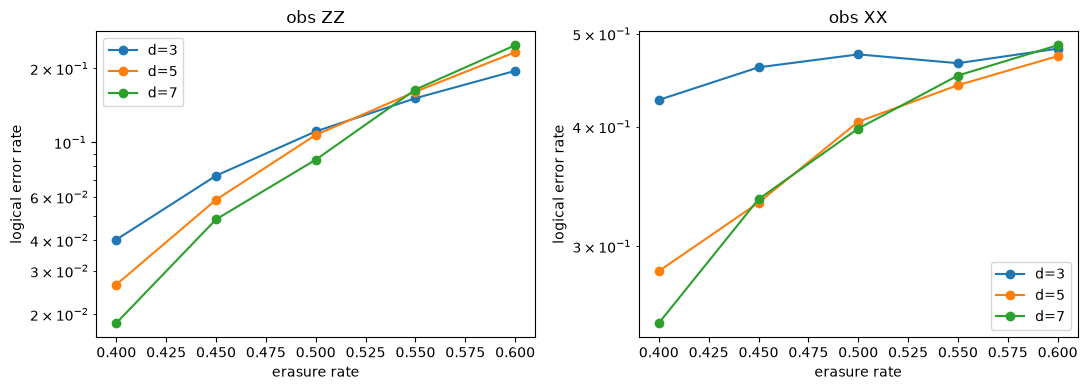

In [9]:
ps = [0.4, 0.45, 0.5, 0.55, 0.6]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, obs in zip(axes, ("ZZ", "XX")):
    rates = erasure_sweep(lambda d: BUILDERS["surgery_bell_prep_fusion"](distance=d, n_cycles=d, observable=obs).circuit, ("graph", "fusion_measurement"), [3, 5, 7], ps, shots=5_000)
    plot_sweep(rates, ps, ax=ax, title=f"obs {obs}")
fig.tight_layout()